Загружаем датасет

In [1]:
import os
import psycopg
import dotenv
import pandas as pd

connection = {"sslmode": "require", "target_session_attrs": "read-write"}
dotenv.load_dotenv()
postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD"),
}
assert all([var_value != "" for var_value in list(postgres_credentials.values())])

connection.update(postgres_credentials)
TABLE_NAME = "clean_flats_price"


with psycopg.connect(**connection) as conn:
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM {TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]


df = pd.DataFrame(data, columns=columns)


Разделяем выборку на обучающую и тестовую. Также удаляем признак "studio" и добавляем признак расстояние до центра Москвы

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
import mlflow
import numpy as np

CENTER_LAT = 55.7520
CENTER_LON = 37.6175

dotenv.load_dotenv()
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

df = df[df['ceiling_height'] != 27]

def haversine_distance(lat, lon):
    R = 6371  

    lat = np.radians(lat)
    lon = np.radians(lon)
    center_lat = np.radians(CENTER_LAT)
    center_lon = np.radians(CENTER_LON)

    dlat = lat - center_lat
    dlon = lon - center_lon

    a = np.sin(dlat / 2) ** 2 + np.cos(center_lat)* np.cos(lat) * np.sin(dlon / 2) ** 2
    

    return 2 * R * np.arcsin(np.sqrt(a))

df_copy = df.copy()
df_copy["distance_to_center"] = haversine_distance(
    df["latitude"],
    df["longitude"],
)

X = df_copy.drop(columns = ['price', 'building_id', 'studio'])
y = df_copy['price']

cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
train_size = 0.8
shuffle=True

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

Добавляем автоматически сгенерированные признаки и преобразованные с помощью RobutScaler

In [6]:
from autofeat import AutoFeatRegressor

autofeat_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "flats_count",
    "ceiling_height",
]
transformations = ["1/", "log",  "sqrt"]

auto = AutoFeatRegressor(
    feateng_steps=2,
    transformations=transformations,
    max_gb=10,
    feateng_cols=autofeat_cols
)
X_train_fe = auto.fit_transform(X_train, y_train)
X_test_fe = auto.transform(X_test)

In [7]:
from sklearn.preprocessing import RobustScaler

rob_feat = [
    "kitchen_area",
    "living_area",
    "total_area",
    "ceiling_height",
]

preprocessor = ColumnTransformer(
    [
        ("robust_scaler", RobustScaler(quantile_range=(10, 90)), rob_feat),
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

X_train_transformed = preprocessor.fit_transform(X_train_fe, y_train,)

X_test_transformed = preprocessor.transform(X_test_fe)


In [9]:
X_test_transformed.shape

(24354, 84)

84 признака имеем в итоге

Отберем сначала с помощью sfs

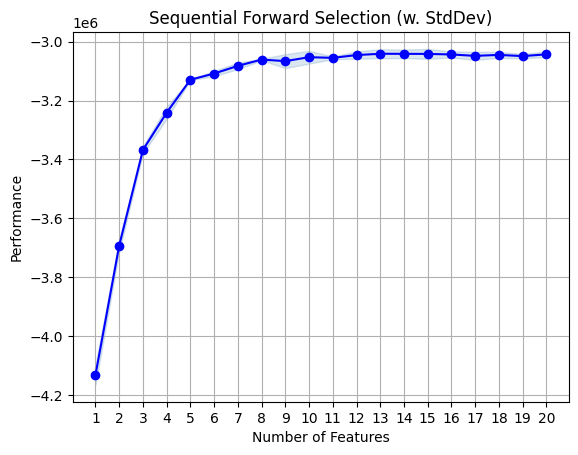

In [16]:
from xgboost import XGBRegressor
from mlxtend.feature_selection import SequentialFeatureSelector
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt

model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)

selection_model = XGBRegressor(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

sample_idx = X_train.sample(n=20_000,random_state=42,).index

X_sfs = X_train_transformed[X_train.index.get_indexer(sample_idx)]

y_sfs = y_train.loc[sample_idx]

sfs = SequentialFeatureSelector(selection_model,
    k_features=20,       
    forward=True,      
    floating=False,     
    scoring='neg_root_mean_squared_error', 
    cv=2,               
    n_jobs=-1)

sfs = sfs.fit(X_sfs, y_sfs)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_dev')


plt.title('Sequential Forward Selection (w. StdDev)')
plt.grid()
plt.show() 

После 10 признаков наблюдается плато

In [41]:
selected_idx_sfs = np.array(sfs.k_feature_idx_)
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sfs]

print(selected_names)

['kitchen_area' 'living_area' 'total_area' 'building_type_int_2.0'
 'building_type_int_5.0' 'id' 'build_year' 'latitude' 'longitude'
 'flats_count' 'distance_to_center' 'total_area/floor'
 'floor*floors_total' 'floors_total*total_area' 'log(rooms)/floors_total'
 'flats_count*floors_total' 'log(total_area)/ceiling_height'
 'ceiling_height*log(total_area)' 'sqrt(kitchen_area)*log(flats_count)'
 'log(flats_count)*log(floors_total)']


Проверим на исходной модели

In [ ]:
import time

X_train_selected = X_train_transformed[:, selected_idx_sfs]
X_test_selected = X_test_transformed[:, selected_idx_sfs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2580758.546290995, 'mae': 1801455.8946784923, 'r2': 0.8311993047633411, 'train_time_sec': 5.34925013099928, 'predict_time_sec': 0.21128798500103585}


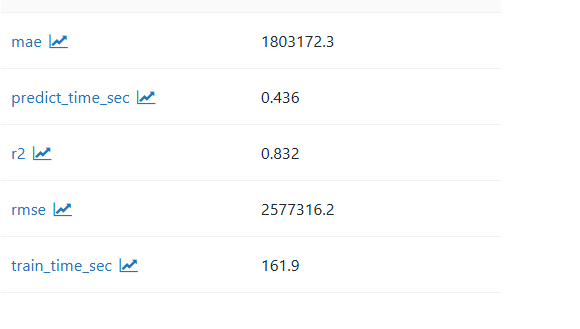 - Модель до отбора<br>
Можно увидеть что показатели модели почти не изменились, но производительность улучшилось вдвое. Среди отобранных признаков оказалось немало автоматически полученных с помощью библиотеки autofeat<br>
Залогируем результат

In [33]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_artifact("fs_assets/sfs_20.png", artifact_path="artifacts")
    mlflow.log_metrics(metrics)

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selction_type", "sfs")
    mlflow.log_param("selected_features",", ".join(selected_names))

Проверим теперь при floating=True

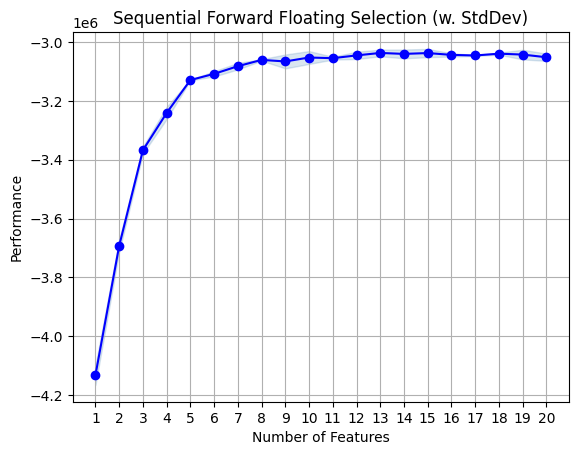

In [28]:
sffs = SequentialFeatureSelector(selection_model,
    k_features=20,       
    forward=True,      
    floating=True,     
    scoring='neg_root_mean_squared_error', 
    cv=2,               
    n_jobs=-1)

sffs = sffs.fit(X_sfs, y_sfs)

fig1 = plot_sfs(sffs.get_metric_dict(), kind='std_dev')


plt.title('Sequential Forward Floating Selection (w. StdDev)')
plt.grid()
plt.show() 

In [40]:
selected_idx_sffs = np.array(sffs.k_feature_idx_)
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sffs]

print(selected_names)

['kitchen_area' 'total_area' 'ceiling_height' 'building_type_int_2.0'
 'building_type_int_4.0' 'building_type_int_5.0' 'building_type_int_6.0'
 'id' 'build_year' 'latitude' 'longitude' 'has_elevator'
 'distance_to_center' 'floor*floors_total' 'floors_total*total_area'
 'kitchen_area*log(rooms)' 'log(rooms)/floors_total'
 'flats_count*floors_total' 'log(total_area)/ceiling_height'
 'ceiling_height*log(total_area)']


In [ ]:
import time

X_train_selected = X_train_transformed[:, selected_idx_sffs]
X_test_selected = X_test_transformed[:, selected_idx_sffs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2571680.586278296, 'mae': 1797766.8085427445, 'r2': 0.8323847476037278, 'train_time_sec': 4.768374438999672, 'predict_time_sec': 0.20717472599972098}


Логируем

In [ ]:
import mlflow


experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_artifact("fs_assets/sffs_20.png", artifact_path="artifacts")
    mlflow.log_metrics(metrics)

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selection_type", "sffs")
    mlflow.log_param("selected_features",", ".join(selected_names))

SFS и SFFS выбрали похожие, но не одинаковые наборы признаков. Оба метода сохранили  признаки площади и местоположения, включая distance_to_center, а также ряд признаков, созданных AutoFeat. После 8–10 признаков качество выходит на плато. Совсем немного лучше оказалась модель на признаках отобранных с помощью sffs.

Теперь объединим признаки и посмотрим на качество модели.

In [ ]:
union_feat = list(set(selected_idx_sffs) | set(selected_idx_sfs))
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[union_feat]
X_train_selected = X_train_transformed[:, union_feat]
X_test_selected = X_test_transformed[:, union_feat]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2571690.562967754, 'mae': 1797319.5904882154, 'r2': 0.8323834470934124, 'train_time_sec': 5.875517813999977, 'predict_time_sec': 0.2122422819993517}


In [ ]:
import mlflow


experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_metrics(metrics)

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selection_type", "union sfs sffs")
    mlflow.log_dict({"selected_features": selected_names.tolist()}, "selected_features.json")

На объединённом наборе признаков модель не продемонстрировала существенного улучшения метрик, поэтому для дальнейшей работы была выбрана модель, обученная на признаках, отобранных методом SFFS.

Регистрируем

In [52]:
selected_idx_sffs = np.array(sffs.k_feature_idx_)

feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sffs]

X_train_selected = X_train_transformed[:, selected_idx_sffs]
X_test_selected = X_test_transformed[:, selected_idx_sffs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    "train_time_sec": train_time,
    "predict_time_sec": predict_time,
}

signature = mlflow.models.infer_signature(X_test_selected, pred)

input_example = X_test_selected[:10]

with mlflow.start_run(
    experiment_id=experiment_id,
    run_name="xgb_selection_model_registry"
) as run:

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("selection_type", "SFFS")

    mlflow.log_metrics(metrics)

    mlflow.log_dict(
        {"selected_features": selected_names.tolist()},
        "selected_features.json"
    )

   
    mlflow.sklearn.log_model(sk_model=preprocessor, artifact_path="preprocessor", pip_requirements="../requirements.txt",)

   
    mlflow.xgboost.log_model(
        xgb_model=model,
        artifact_path="model",
        signature=signature,
        input_example=input_example,
        pip_requirements="../requirements.txt",
        registered_model_name="flats_price_model",
        await_registration_for=60,
    )

2026/08/18 20:53:43 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/xgboost/sklearn.py:1116: UserWarning: [20:53:43] WARNING: /__w/xgboost/xgboost/src/c_api/c_api.cc:1573: Saving model in the UBJSON format as default.  You can use a file extension: `json` or `ubj` to choose between formats.
  self.get_booster().save_model(fname)
Registered model 'flats_price_model' already exists. Creating a new version of this model...
2026/08/18 20:53:44 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: flats_price_model, version 3
Created version '3' of model 'flats_price_model'.
